# O pênalti como jogo de soma zero
### Estratégia ótima por Programação Linear e a ordem dos batedores na disputa de pênaltis

**COS360/COM361 — Otimização — Projeto final**
Autor: Thiago Moutinho

---

## 1. Introdução

### O problema
Um pênalti dura menos de meio segundo: a bola leva cerca de 0,4 s para chegar ao gol, tempo curto
demais para o goleiro reagir depois de ver o chute. Por isso, **batedor e goleiro decidem
praticamente ao mesmo tempo**: o batedor escolhe um canto (esquerda, meio ou direita) e o goleiro
escolhe para onde pular. Se o goleiro acerta o lado, a chance de defesa sobe muito; se erra, o gol
é quase certo.

Isso cria o dilema clássico: se um batedor **sempre** chuta no mesmo canto, os goleiros estudam e
passam a pular para lá. A melhor defesa é ser **imprevisível** — mas imprevisível *com que
proporções*? Este projeto responde, usando Programação Linear:

> **Com que probabilidade o batedor deve escolher cada canto (e o goleiro cada lado) para garantir
> a maior chance de gol possível contra qualquer adversário?**

E, na segunda parte, uma pergunta que todo torcedor do Fluminense já se fez numa disputa de
pênaltis:

> **Quais batedores escalar, e em que ordem, para maximizar a chance de vencer a disputa?**

### Um pouco de história
- **1890–1891** — o goleiro irlandês William McCrum propõe o pênalti, que a International Football
  Association Board (IFAB) incorpora às regras em junho de 1891.
- **1928** — fora do futebol, **John von Neumann** prova o **Teorema Minimax**: todo jogo de soma
  zero entre dois jogadores tem um valor $v$ e estratégias mistas que o garantem [1]. Junto com
  Morgenstern, funda a Teoria dos Jogos em 1944 [2].
- **1951** — **George Dantzig** mostra que resolver um jogo de soma zero é equivalente a resolver um
  Programa Linear: os dois jogadores correspondem a um par **primal/dual** [3, 4].
- **1970** — a IFAB aprova oficialmente a **disputa por pênaltis** para desempatar jogos
  eliminatórios (em Copas do Mundo, ela aparece pela primeira vez em 1982).
- **2002–2003** — Chiappori, Levitt e Groseclose [5] e Palacios-Huerta [6] analisam milhares de
  pênaltis de ligas europeias e concluem que **jogadores profissionais jogam muito perto da
  estratégia minimax** — um dos testes mais famosos da Teoria dos Jogos com dados reais.
- **2010** — Apesteguia e Palacios-Huerta [7] reportam que o time que **bate primeiro** numa
  disputa vence cerca de 60% das vezes; Kocher, Lenz e Sutter [8], com uma amostra maior, não
  encontram vantagem significativa. O debate continua.

### Aplicações atuais
A mesma matemática aparece onde for preciso **ser imprevisível de forma ótima**: patrulhas de
segurança em aeroportos sorteadas por PL [9], pôquer [10], saque e recepção no tênis, e a
preparação de goleiros — que hoje recebem listas com o histórico de cobranças dos adversários.

## 2. Modelo Matemático

### 2.1 Dados: a matriz de probabilidades de gol
Cada jogador tem 3 ações: **E** (esquerda), **M** (meio), **D** (direita). Seguindo a convenção
dos dados que usaremos, **os lados são sempre do ponto de vista do goleiro**.

Seja $P_{ij}$ a probabilidade de gol quando o batedor chuta em $i$ e o goleiro vai para $j$:

$$P = \begin{pmatrix} P_{EE} & P_{EM} & P_{ED} \\ P_{ME} & P_{MM} & P_{MD} \\ P_{DE} & P_{DM} & P_{DD}\end{pmatrix}.$$

O batedor quer **maximizar** a probabilidade de gol e o goleiro quer **minimizá-la**: o que um
ganha o outro perde, então é um jogo de **soma zero**. (Diferente de jogos simétricos, aqui o
valor do jogo **não** é zero: é a chance de gol de equilíbrio.)

### 2.2 Estratégias mistas e o problema maximin
O batedor escolhe uma distribuição $x = (x_E, x_M, x_D)$, com $x \ge 0$ e $\sum_i x_i = 1$. Contra
um goleiro que vai para $j$, a chance de gol é $\sum_i P_{ij}x_i$. O batedor quer o **melhor pior
caso**:

$$\max_{x \in \Delta} \; \min_{j} \; \sum_i P_{ij}\,x_i .$$

Como o $\min$ não é linear, usamos o truque da aula de **minimax** [13]: uma variável $v$ que fica
abaixo de todos os termos. O truque funciona porque, para cada $x$ fixo, o maior $v$ que satisfaz
$v \le \sum_i P_{ij}x_i$ para todo $j$ é exatamente $\min_j \sum_i P_{ij}x_i$: as restrições impedem $v$
de passar do menor termo, e a maximização o empurra até encostar nele. Assim, para cada $x$, (P) vale
o mesmo que o maximin, e os dois problemas têm o mesmo ótimo:

$$
\boxed{
\begin{aligned}
\text{(P)}\quad \max_{x,\,v}\quad & v\\
\text{s.a.}\quad & \textstyle\sum_i P_{ij}\,x_i \;\ge\; v, \qquad j \in \{E, M, D\}\\
& \textstyle\sum_i x_i = 1, \qquad x \ge 0
\end{aligned}}
$$

### 2.3 O dual é o goleiro
O dual de (P) é o problema do goleiro, que escolhe $y = (y_E, y_M, y_D)$:

$$
\begin{aligned}
\text{(D)}\quad \min_{y,\,w}\quad & w\\
\text{s.a.}\quad & \textstyle\sum_j P_{ij}\,y_j \;\le\; w, \qquad i \in \{E, M, D\}\\
& \textstyle\sum_j y_j = 1, \qquad y \ge 0
\end{aligned}
$$

Cada restrição de (P) (um pulo do goleiro) vira uma variável $y_j$ de (D), e a variável livre $v$
vira a restrição $\sum_j y_j = 1$. Pela **dualidade forte** [13], $v^* = w^*$: a chance de gol que o batedor consegue garantir é exatamente a
que o goleiro consegue impedir de ser ultrapassada. Esse é o Teorema Minimax de von Neumann.

### 2.4 Uma previsão testável: indiferença
Pelas **folgas complementares**, se o batedor usa um canto com probabilidade positiva ($x_i^* > 0$),
a restrição dual correspondente é ativa: contra o goleiro ótimo, **todos os cantos usados dão a
mesma chance de gol**. É isso que os economistas testaram com dados reais [5, 6] — e que testamos
na Seção 3.5.

### 2.5 Aproximações
- **Escolha simultânea:** o goleiro não reage ao chute (razoável: a bola é rápida demais).
- **Três ações:** na realidade o canto é contínuo (alto/baixo, mais ou menos aberto).
- **Matriz única:** na parte 1, todos os batedores e goleiros são "médios"; na parte 2 cada
  batedor terá sua própria matriz.
- **Sem pé dominante:** os dados da liga não distinguem destros e canhotos. Para um destro, o lado
  "natural" é a esquerda **do batedor**, ou seja, a **direita do goleiro** [11]. Na Seção 3.7
  usamos o pé anotado nos dados do Fluminense para tratar isso.
- **Probabilidades estimadas:** algumas combinações (ex.: chute no meio com goleiro parado)
  têm pouquíssimas observações — tratamos isso com regularização na Seção 3.4.

## 3. Solução

### 3.1 Ferramentas
**PuLP** para escrever os PLs e o solver **HiGHS** (que usa o método simplex) para resolvê-los;
**NumPy** e **pandas** para os dados, **SciPy** para o teste qui-quadrado e **Matplotlib** para os
gráficos. As versões estão em `requirements.txt`.

In [1]:
import itertools
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

import os
import time
from math import perm

SOLVER = pulp.HiGHS(msg=False)

# O HiGHS imprime um aviso de licença na primeira execução; resolvemos um PL trivial em silêncio
_saida, _nulo = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_nulo, 1)
try:
    _aquece = pulp.LpProblem("aquecimento", pulp.LpMinimize)
    _x = pulp.LpVariable("x", lowBound=0)
    _aquece += _x
    _aquece.solve(SOLVER)
finally:
    os.dup2(_saida, 1); os.close(_nulo); os.close(_saida)
ACOES = ["E", "M", "D"]          # esquerda, meio, direita (vistos pelo goleiro)

# Estilo dos gráficos
AZUL, LARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110,
})

In [2]:
def resolver_batedor(P, nomes_linha=ACOES, nomes_coluna=ACOES):
    '''(P): max v  s.a.  sum_i P[i,j] x_i >= v  para todo j,  sum x = 1,  x >= 0.'''
    P = np.asarray(P, float); n, m = P.shape
    prob = pulp.LpProblem("batedor", pulp.LpMaximize)
    x = [pulp.LpVariable(f"x_{i}", lowBound=0) for i in range(n)]
    v = pulp.LpVariable("v")
    prob += v
    for j in range(m):                                   # pior caso: cada escolha do goleiro
        prob += pulp.lpSum(P[i, j] * x[i] for i in range(n)) >= v
    prob += pulp.lpSum(x) == 1
    prob.solve(SOLVER)
    assert pulp.LpStatus[prob.status] == "Optimal"
    return pd.Series([max(xi.value(), 0.0) for xi in x], index=nomes_linha), v.value()


def resolver_goleiro(P, nomes_linha=ACOES, nomes_coluna=ACOES):
    '''(D): min w  s.a.  sum_j P[i,j] y_j <= w  para todo i,  sum y = 1,  y >= 0.'''
    P = np.asarray(P, float); n, m = P.shape
    prob = pulp.LpProblem("goleiro", pulp.LpMinimize)
    y = [pulp.LpVariable(f"y_{j}", lowBound=0) for j in range(m)]
    w = pulp.LpVariable("w")
    prob += w
    for i in range(n):                                   # melhor caso: cada canto do batedor
        prob += pulp.lpSum(P[i, j] * y[j] for j in range(m)) <= w
    prob += pulp.lpSum(y) == 1
    prob.solve(SOLVER)
    assert pulp.LpStatus[prob.status] == "Optimal"
    return pd.Series([max(yj.value(), 0.0) for yj in y], index=nomes_coluna), w.value()

### 3.2 Os dados
Usamos a base de **549 pênaltis** da liga espanhola (temporadas 2005/06 a 2014/15) compilada por
Sentana Lledó [11]. A tabela abaixo reproduz, para cada combinação (canto do batedor, lado do
goleiro), o número de cobranças e o número de gols, reconstruídos a partir das frequências e taxas
de conversão publicadas (Tabela 1 do trabalho). Os totais conferem: 549 cobranças, 474 gols
(86,34%).

In [3]:
# (batedor, goleiro): (cobranças, gols)    -- Sentana Lledó (2015), Tabela 1
dados = {
    ("E", "E"): (113, 79),  ("E", "M"): (14, 13), ("E", "D"): (147, 144),
    ("M", "E"): (20, 20),   ("M", "M"): (6, 0),   ("M", "D"): (13, 12),
    ("D", "E"): (115, 110), ("D", "M"): (5, 5),   ("D", "D"): (116, 91),
}
N = pd.DataFrame(0, index=ACOES, columns=ACOES)   # cobranças
G = pd.DataFrame(0, index=ACOES, columns=ACOES)   # gols
for (i, j), (n, g) in dados.items():
    N.loc[i, j], G.loc[i, j] = n, g

print("Total de cobranças:", N.values.sum(), "| gols:", G.values.sum(),
      f"| conversão: {G.values.sum() / N.values.sum():.2%}")
N.index.name, N.columns.name = "batedor", "goleiro"
N

Total de cobranças: 549 | gols: 474 | conversão: 86.34%


goleiro,E,M,D
batedor,,,
E,113,14,147
M,20,6,13
D,115,5,116


### 3.3 Exemplo pequeno — o jogo 2×2 (só esquerda e direita)
Ignorando o meio (raro: só 7% dos chutes), ficamos com 4 probabilidades. Neste caso dá para
resolver **à mão**: o batedor deve chutar à esquerda com probabilidade $p$ que deixa o goleiro
**indiferente** entre os lados:
$$p\,P_{EE} + (1-p)\,P_{DE} = p\,P_{ED} + (1-p)\,P_{DD}
\;\;\Longrightarrow\;\;
p^* = \frac{P_{DD} - P_{DE}}{P_{EE} - P_{ED} - P_{DE} + P_{DD}}.$$
Analogamente para o goleiro. Vamos comparar a fórmula com o PL.

In [4]:
P2 = (G / N).loc[["E", "D"], ["E", "D"]].values
print("Matriz 2x2 de probabilidade de gol:\n", pd.DataFrame(P2, index=["E", "D"], columns=["E", "D"]).round(3), "\n")

(pEE, pED), (pDE, pDD) = P2
p_mao = (pDD - pDE) / (pEE - pED - pDE + pDD)          # batedor
q_mao = (pDD - pED) / (pEE - pED - pDE + pDD)          # goleiro
v_mao = p_mao * pEE + (1 - p_mao) * pDE

x2, v2 = resolver_batedor(P2, ["E", "D"], ["E", "D"])
y2, w2 = resolver_goleiro(P2, ["E", "D"], ["E", "D"])
print(f"À mão : batedor chuta E com {p_mao:.3f}, goleiro pula E com {q_mao:.3f}, chance de gol {v_mao:.4f}")
print(f"PL    : batedor chuta E com {x2['E']:.3f}, goleiro pula E com {y2['E']:.3f}, primal {v2:.4f} = dual {w2:.4f}")

Matriz 2x2 de probabilidade de gol:
        E      D
E  0.699  0.980
D  0.957  0.784 

À mão : batedor chuta E com 0.380, goleiro pula E com 0.431, chance de gol 0.8587
PL    : batedor chuta E com 0.380, goleiro pula E com 0.431, primal 0.8587 = dual 0.8587


### 3.4 O jogo completo 3×3 — e o problema das células pequenas
A estimativa ingênua $\hat P_{ij} = \text{gols}_{ij} / \text{cobranças}_{ij}$ é ruim onde há poucas
cobranças: "chute no meio com goleiro parado" tem **6** observações e **0** gols, e "direita com
goleiro parado" tem **5** com 100%. Os valores em si fazem sentido (goleiro parado defende quase todo
chute no meio; goleiro parado não alcança chute no canto), mas **6 chutes não bastam para afirmá-los**:
o intervalo de 95% de confiança para 0 gols em 6 vai de 0% a 46%, e para 5 em 5, de 48% a 100%.

**Regularização por encolhimento.** Agrupamos as células em classes de situações parecidas e
"puxamos" cada célula para o valor de referência da sua classe, somando $m$ cobranças fictícias:
$$\tilde P_{ij} = \frac{\text{gols}_{ij} + m\,\bar p_{\text{classe}(ij)}}{\text{cobranças}_{ij} + m}.$$
Células com muitos dados quase não mudam; células com poucos dados ficam perto da referência.
Esse estimador é a solução de um mínimos quadrados regularizado,
$\min_p \sum_t (g_t - p)^2 + m\,(p - \bar p)^2$ com $g_t = 1$ se a cobrança $t$ foi gol: o primeiro
termo é o ajuste aos dados e o segundo penaliza afastar-se da referência, com peso $m$ (é a troca da
aula de *regularization* [13]).

As três classes:

| classe | células | referência $\bar p$ |
|---|---|---|
| goleiro **pulou e acertou** o lado | E×E, D×D | média dos dados da classe |
| goleiro **errou** o lado | fora da diagonal | média dos dados da classe |
| goleiro **parado** e chute **no meio** | M×M | **conhecimento prévio**: `P_MM_PRIOR = 0.15` |

A célula M×M fica numa classe própria porque é uma situação diferente das outras da diagonal: o
goleiro não precisa se jogar, a bola vem nele. Juntá-la com E×E e D×D (a escolha mais simples)
puxaria a chance para ~72%, que é a taxa de quem **pulou e chegou** na bola, e o
resultado (0,45) é alto demais para um goleiro parado. Como há só 6 dados, a referência vem do
conhecimento do jogo: um goleiro parado defende a grande maioria dos chutes no meio, exceto os
muito altos ou fortes, e por isso usamos 15%. É o raciocínio **bayesiano**: uma crença inicial que
os dados corrigem. A escolha é um julgamento, e a tabela de sensibilidade abaixo mostra quanto ela
importa.

In [5]:
P_MM_PRIOR = 0.15   # referência para "goleiro parado, chute no meio" (conhecimento prévio, ver texto)

def estimar_P(N, G, m=10, p_mm=P_MM_PRIOR):
    N, G = N.values.astype(float), G.values.astype(float)
    acertou = np.eye(3, dtype=bool); acertou[1, 1] = False   # E×E e D×D: goleiro pulou e acertou
    errou = ~np.eye(3, dtype=bool)                            # goleiro foi para outro lado
    p_acertou = G[acertou].sum() / N[acertou].sum()
    p_errou = G[errou].sum() / N[errou].sum()
    referencia = np.where(errou, p_errou, p_acertou)
    referencia[1, 1] = p_mm                                   # M×M: goleiro parado, chute no meio
    return pd.DataFrame((G + m * referencia) / (N + m), index=ACOES, columns=ACOES), p_acertou, p_errou

P_bruta = G / N
P_reg, p_ac, p_er = estimar_P(N, G, m=10)
print(f"Referências: 'pulou e acertou' {p_ac:.3f} | 'errou' {p_er:.3f} | 'parado, chute no meio' {P_MM_PRIOR:.3f}\n")
pd.concat({"bruta": P_bruta.round(3), "regularizada (m=10)": P_reg.round(3)}, axis=1)

Referências: 'pulou e acertou' 0.742 | 'errou' 0.968 | 'parado, chute no meio' 0.150



bruta               regularizada (m=10)              
       E      M      D                   E      M      D
E  0.699  0.929  0.980               0.703  0.945  0.979
M  1.000  0.000  0.923               0.989  0.094  0.943
D  0.957  1.000  0.784               0.957  0.979  0.781

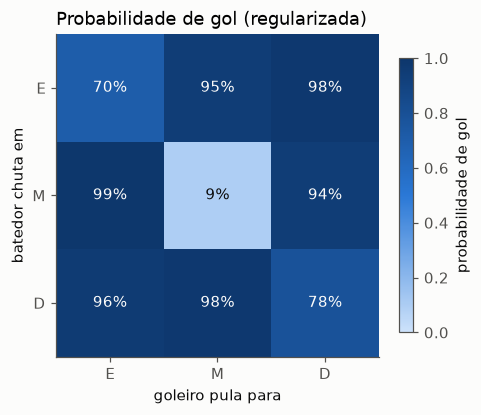

In [6]:
def plotar_matriz(P, titulo):
    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    from matplotlib.colors import LinearSegmentedColormap
    seq = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])
    im = ax.imshow(P, cmap=seq, vmin=0, vmax=1)
    ax.set_xticks(range(3), ["E", "M", "D"]); ax.set_yticks(range(3), ["E", "M", "D"])
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{P[i, j]:.0%}", ha="center", va="center", fontsize=10,
                    color="#0b0b0b" if P[i, j] < 0.55 else "#fcfcfb")
    ax.set_xlabel("goleiro pula para"); ax.set_ylabel("batedor chuta em")
    ax.set_title(titulo, loc="left")
    fig.colorbar(im, ax=ax, label="probabilidade de gol", shrink=0.85)
    plt.tight_layout(); plt.show()

plotar_matriz(P_reg.values, "Probabilidade de gol (regularizada)")

In [7]:
x3, v3 = resolver_batedor(P_reg.values)
y3, w3 = resolver_goleiro(P_reg.values)
print(f"Valor do jogo (chance de gol no equilíbrio): primal {v3:.4f} = dual {w3:.4f}\n")
print("Batedor ótimo :", x3.round(3).to_dict())
print("Goleiro ótimo :", y3.round(3).to_dict())

# Indiferença (folgas complementares): contra o goleiro ótimo, cada canto usado rende o mesmo
print("\nChance de gol de cada canto contra o goleiro ótimo:",
      pd.Series(P_reg.values @ y3.values, index=ACOES).round(4).to_dict())

Valor do jogo (chance de gol no equilíbrio): primal 0.8697 = dual 0.8697

Batedor ótimo : {'E': 0.358, 'M': 0.11, 'D': 0.532}
Goleiro ótimo : {'E': 0.382, 'M': 0.107, 'D': 0.511}

Chance de gol de cada canto contra o goleiro ótimo: {'E': 0.8697, 'M': 0.8697, 'D': 0.8697}


**Sensibilidade à regularização.** Como a solução muda com a força $m$ do encolhimento
($m = 0$ é a estimativa bruta) e com a referência escolhida para M×M?

In [8]:
linhas = []
for m in [0, 2, 5, 10, 20, 50]:
    Pm, _, _ = estimar_P(N, G, m=m)
    xm, vm = resolver_batedor(Pm.values)
    ym, _ = resolver_goleiro(Pm.values)
    linhas.append({"m": m, "valor": vm,
                   **{f"batedor {a}": xm[a] for a in ACOES},
                   **{f"goleiro {a}": ym[a] for a in ACOES}})
display(pd.DataFrame(linhas).set_index("m").round(3))

# referência de M×M (com m = 10); 0.723 = juntar M×M com "goleiro acertou" (a escolha mais simples)
linhas = []
for ref in [0.05, 0.15, 0.30, 0.50, 0.723]:
    Pm, _, _ = estimar_P(N, G, m=10, p_mm=ref)
    xm, vm = resolver_batedor(Pm.values)
    linhas.append({"referência M×M": ref, "P_MM estimada": Pm.values[1, 1], "valor": vm,
                   **{f"batedor {a}": xm[a] for a in ACOES}})
pd.DataFrame(linhas).set_index("referência M×M").round(3)

,valor,batedor E,batedor M,batedor D,goleiro E,goleiro M,goleiro D
m,,,,,,,
0,0.869,0.358,0.105,0.537,0.378,0.090,0.532
2,0.869,0.358,0.106,0.536,0.379,0.096,0.525
5,0.869,0.357,0.108,0.535,0.380,0.102,0.518
10,0.870,0.358,0.110,0.532,0.382,0.107,0.511
20,0.870,0.361,0.112,0.526,0.387,0.112,0.501
50,0.870,0.372,0.116,0.512,0.397,0.117,0.486


,P_MM estimada,valor,batedor E,batedor M,batedor D
referência M×M,,,,,
0.050,0.031,0.869,0.360,0.103,0.537
0.150,0.094,0.870,0.358,0.110,0.532
0.300,0.188,0.871,0.355,0.121,0.524
0.500,0.312,0.873,0.349,0.141,0.510
0.723,0.452,0.876,0.340,0.173,0.487


### 3.5 O modelo explica o comportamento real?
Comparamos as frequências **previstas** pelo equilíbrio com as **observadas** nos 549 pênaltis.

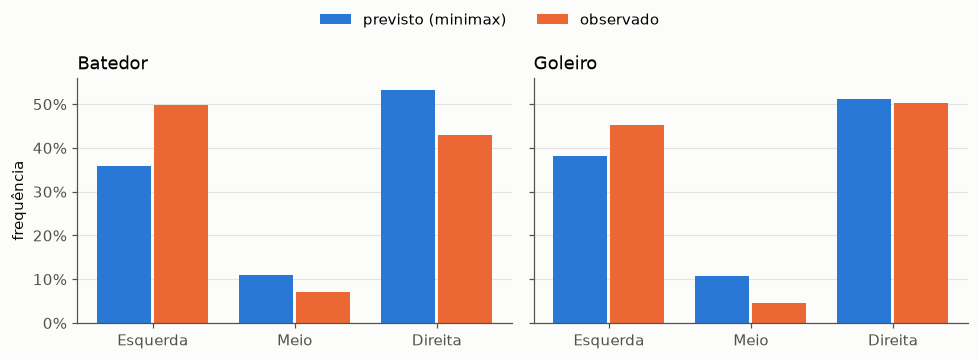

,batedor previsto,batedor observado,goleiro previsto,goleiro observado
E,0.358,0.499,0.382,0.452
M,0.110,0.071,0.107,0.046
D,0.532,0.430,0.511,0.503


In [9]:
obs_batedor = N.sum(axis=1) / N.values.sum()
obs_goleiro = N.sum(axis=0) / N.values.sum()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
for ax, prev, obs, titulo in [(axes[0], x3, obs_batedor, "Batedor"), (axes[1], y3, obs_goleiro, "Goleiro")]:
    pos = np.arange(3)
    ax.bar(pos - 0.2, prev.values, width=0.38, color=AZUL, label="previsto (minimax)")
    ax.bar(pos + 0.2, obs.values, width=0.38, color=LARANJA, label="observado")
    ax.set_xticks(pos, ["Esquerda", "Meio", "Direita"]); ax.set_title(titulo, loc="left")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda t, _: f"{t:.0%}"))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("frequência")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

pd.DataFrame({"batedor previsto": x3, "batedor observado": obs_batedor,
              "goleiro previsto": y3, "goleiro observado": obs_goleiro}).round(3)

**Teste da indiferença.** A previsão mais direta da teoria (folgas complementares, Seção 2.4) é
que, no equilíbrio, **todos os cantos usados dão a mesma chance de gol**, e todos os lados usados
pelo goleiro também. Isso se testa direto nos dados, sem resolver PL nenhum: comparamos a conversão
por canto do batedor e por lado do goleiro com um teste qui-quadrado de homogeneidade (hipótese
nula: mesma conversão em todas as ações). É o teste de Chiappori et al. [5] e Palacios-Huerta [6].

In [10]:
from scipy.stats import chi2_contingency

def teste_indiferenca(gols, cobrancas, rotulos):
    """Conversão por ação e teste qui-quadrado de homogeneidade (H0: mesma conversão em todas)."""
    gols, cobrancas = np.asarray(gols, float), np.asarray(cobrancas, float)
    _, p_valor, _, _ = chi2_contingency(np.column_stack([gols, cobrancas - gols]))
    tabela = pd.DataFrame({"cobranças": cobrancas.astype(int), "conversão": gols / cobrancas}, index=rotulos)
    return tabela, p_valor

for quem, eixo in [("batedor (canto do chute)", 1), ("goleiro (lado do pulo)", 0)]:
    tabela, p_valor = teste_indiferenca(G.sum(axis=eixo), N.sum(axis=eixo), ACOES)
    print(f"Conversão por ação do {quem}: p-valor = {p_valor:.3f}")
    display(tabela.round(3))

# Goleiro só entre os lados (sem o meio, que tem poucas observações)
_, p_lados = teste_indiferenca(G.sum(axis=0)[["E", "D"]], N.sum(axis=0)[["E", "D"]], ["E", "D"])
print(f"Goleiro, só E × D: p-valor = {p_lados:.3f}")

Conversão por ação do batedor (canto do chute): p-valor = 0.671


,cobranças,conversão
E,274,0.861
M,39,0.821
D,236,0.873


Conversão por ação do goleiro (lado do pulo): p-valor = 0.023


,cobranças,conversão
E,248,0.843
M,25,0.720
D,276,0.895


Goleiro, só E × D: p-valor = 0.100


**Leitura.** Para o batedor, a teoria passa no teste: a conversão é praticamente a mesma nos três
cantos (p ≈ 0,67), como prevê o equilíbrio. Para o goleiro, pular para a esquerda ou para a direita
também dá conversões estatisticamente iguais (p ≈ 0,10), mas **ficar no meio** segura bem mais
(72% de gols, em só 25 casos). Isso é coerente com o próprio modelo: se ficar no meio rende mais, o
goleiro deveria ficar mais vezes, e o equilíbrio de fato recomenda 11% de goleiro no meio, contra os
4,6% observados. Com 25 observações, porém, essa célula é a menos confiável da tabela.

### 3.6 Da cobrança à disputa de pênaltis

Agora usamos o PL como **bloco de construção**. Cada batedor $k$ tem a sua própria matriz $P^{(k)}$
(uns são melhores no canto natural, outros batem bem no meio, outros são fracos de um lado), e o
valor do seu jogo $v_k$ é a **chance de gol que ele garante** contra um goleiro que conhece seus
pontos fortes e joga otimamente.

⚠️ **Os batedores abaixo são fictícios**: perfis construídos alterando a matriz média para ilustrar
o método. Com dados reais de um elenco (ex.: o histórico de cobranças de cada jogador), basta
trocar as matrizes.

In [11]:
P_base = P_reg.values

def perfil(ajustes):
    '''Copia a matriz média e soma ajustes {(i, j): delta}; mantém em [0, 1].'''
    P = P_base.copy()
    for (i, j), d in ajustes.items():
        P[ACOES.index(i), ACOES.index(j)] += d
    return np.clip(P, 0, 1)

elenco = {
    "Batedor A (especialista)":     perfil({("E", "E"): +0.10, ("D", "D"): +0.10}),
    "Batedor B (bate forte no E)":  perfil({("E", "E"): +0.15}),
    "Batedor C (cavadinha)":        perfil({("M", "M"): +0.40}),
    "Batedor D (médio)":            perfil({}),
    "Batedor E (fraco no D)":       perfil({("D", "D"): -0.20, ("D", "E"): -0.05}),
    "Batedor F (inseguro)":         perfil({("E", "E"): -0.10, ("D", "D"): -0.10}),
    "Batedor G (zagueiro)":         perfil({("E", "E"): -0.15, ("D", "D"): -0.15, ("E", "D"): -0.05, ("D", "E"): -0.05}),
}

linhas = []
for nome, Pk in elenco.items():
    xk, vk = resolver_batedor(Pk)
    linhas.append({"batedor": nome, "chance garantida v_k": vk, **{f"x_{a}": xk[a] for a in ACOES}})
tab_elenco = pd.DataFrame(linhas).set_index("batedor").sort_values("chance garantida v_k", ascending=False)
tab_elenco.round(3)

,chance garantida v_k,x_E,x_M,x_D
batedor,,,,
Batedor A (especialista),0.914,0.295,0.062,0.643
Batedor B (bate forte no E),0.901,0.554,0.066,0.379
Batedor C (cavadinha),0.878,0.337,0.185,0.478
Batedor D (médio),0.870,0.358,0.110,0.532
Batedor F (inseguro),0.831,0.370,0.153,0.478
Batedor E (fraco no D),0.824,0.469,0.157,0.374
Batedor G (zagueiro),0.797,0.356,0.192,0.452


#### Probabilidade exata de vencer a disputa
Regras: cada time cobra 5 pênaltis, alternadamente; a disputa termina assim que um time não pode
mais alcançar o outro. Empatando após 5, segue a **morte súbita** (uma cobrança de cada até que um
converta e o outro não).

Calculamos a probabilidade de vitória **exatamente** por recursão sobre o estado
$(\text{gols}_A, \text{gols}_B, \text{cobranças}_A, \text{cobranças}_B)$: de cada estado, o próximo
batedor converte com probabilidade $p$ e erra com $1-p$. A morte súbita é truncada em 30 rodadas
(o erro é desprezível). Na morte súbita batem os batedores restantes da lista e, depois deles, o
"resto do time" (demais jogadores e goleiro), com uma chance média fixa.

Incluímos ainda um **efeito de pressão**: quando **errar significa perder imediatamente**, a
chance do batedor cai $\delta_k$. Jordet et al. [12] encontraram queda expressiva na conversão
nessas situações; os valores de $\delta_k$ abaixo são **ilustrativos**.

In [12]:
def decidido(ga, gb, ca, cb):
    '''Retorna 'A', 'B' ou None dado gols e cobranças de cada time (A bate primeiro).'''
    if ca <= 5 and cb <= 5:                       # tempo regulamentar (5 cobranças)
        if ga + (5 - ca) < gb: return "B"
        if gb + (5 - cb) < ga: return "A"
        return None
    if ca == cb and ga != gb:                     # morte súbita: rodada completa
        return "A" if ga > gb else "B"
    return None


def completar(p, d, resto, n):
    '''Estende as listas até n cobranças; quem não foi listado vale `resto` = (p, delta).'''
    d = list(d) if d is not None else [0.0] * len(p)
    return list(p) + [resto[0]] * (n - len(p)), d + [resto[1]] * (n - len(d))


def funcao_valor(pA, pB, dA=None, dB=None, restoA=None, restoB=None, max_cobrancas=35):
    '''Devolve a função V(ga, gb, ca, cb) = probabilidade exata de o time A (que bate primeiro)
    vencer a partir de um estado da disputa (gols e cobranças de cada time).
    pA, pB         : chance de gol dos batedores listados, na ordem (6o em diante = morte súbita)
    dA, dB         : queda de chance sob pressão ("se errar, perde") de cada um
    restoA, restoB : (p, delta) das cobranças além da lista (resto do time); padrão = média da lista
    '''
    restoA = restoA or (float(np.mean(pA)), float(np.mean(dA)) if dA else 0.0)
    restoB = restoB or (float(np.mean(pB)), float(np.mean(dB)) if dB else 0.0)
    pA, dA = completar(pA, dA, restoA, max_cobrancas + 1)
    pB, dB = completar(pB, dB, restoB, max_cobrancas + 1)

    @lru_cache(maxsize=None)
    def f(ga, gb, ca, cb):
        vencedor = decidido(ga, gb, ca, cb)
        if vencedor: return 1.0 if vencedor == "A" else 0.0
        if ca >= max_cobrancas: return 0.5        # truncamento (probabilidade desprezível)
        if ca == cb:                              # vez do time A
            k = ca
            pressao = decidido(ga, gb, ca + 1, cb) == "B"     # errar => perde
            p = pA[k] - (dA[k] if pressao else 0.0)
            return p * f(ga + 1, gb, ca + 1, cb) + (1 - p) * f(ga, gb, ca + 1, cb)
        else:                                     # vez do time B
            k = cb
            pressao = decidido(ga, gb, ca, cb + 1) == "A"
            p = pB[k] - (dB[k] if pressao else 0.0)
            return p * f(ga, gb + 1, ca, cb + 1) + (1 - p) * f(ga, gb, ca, cb + 1)

    return f


def prob_vitoria(pA, pB, dA=None, dB=None, restoA=None, restoB=None, max_cobrancas=35):
    '''Probabilidade exata de o time A (que bate primeiro) vencer: V no estado inicial.'''
    return funcao_valor(pA, pB, dA, dB, restoA, restoB, max_cobrancas)(0, 0, 0, 0)

# Teste de sanidade: dois times idênticos sem pressão -> 50%
print(f"Times iguais (p = {v3:.3f}), sem pressão: P(A vence) = {prob_vitoria([v3] * 11, [v3] * 11):.4f}")

Times iguais (p = 0.870), sem pressão: P(A vence) = 0.5000


#### A ordem importa?
**Sem efeito de pressão, a ordem dos 5 primeiros batedores não importa.** Se as cobranças são
independentes, o número total de gols de cada time nas 5 cobranças tem a mesma distribuição em
qualquer ordem, e o encerramento antecipado não muda o vencedor (só para quando o resultado já
está decidido). Verificamos numericamente com todas as $5! = 120$ ordens:

In [13]:
v = tab_elenco["chance garantida v_k"]
cinco = list(v.index[:5])                         # os 5 com maior chance garantida
reservas = [v[nome] for nome in v.index[5:]]      # morte súbita
adversario = [v3] * 11                            # adversário "médio" da liga
RESTO = (0.80, 0.12)                              # resto do nosso time na morte súbita (ilustrativo)

probs = [prob_vitoria([v[n] for n in ordem] + reservas, adversario, restoA=RESTO)
         for ordem in itertools.permutations(cinco)]
print(f"Sem pressão: min = {min(probs):.6f}, max = {max(probs):.6f}  (todas iguais)")

Sem pressão: min = 0.467732, max = 0.467732  (todas iguais)


**Com pressão, a ordem passa a importar**, porque batedores diferentes sentem a pressão de forma
diferente e as cobranças decisivas tendem a cair nas últimas posições. Agora vale otimizar:
escolher **quais 5** dos 7 e **em que ordem** — $7!/2! = 2520$ escalações, que enumeramos
exatamente.

In [14]:
# Queda de conversão sob pressão (ilustrativa): o "especialista" é frio, o zagueiro sente muito
delta = {
    "Batedor A (especialista)": 0.02, "Batedor B (bate forte no E)": 0.15,
    "Batedor C (cavadinha)": 0.20,    "Batedor D (médio)": 0.08,
    "Batedor E (fraco no D)": 0.10,   "Batedor F (inseguro)": 0.20,
    "Batedor G (zagueiro)": 0.12,
}
delta_adv = [0.08] * 11


def otimizar_escalacao(v, delta, adversario, delta_adv, resto=RESTO, bate_primeiro=True):
    """Enumera todas as escolhas ordenadas de 5 batedores e devolve (prob, ordem) da melhor
    e da pior. Quem não está entre os 5 bate na morte súbita, na ordem de v."""
    def avaliar(ordem):
        seq = list(ordem) + [n for n in v.index if n not in ordem]
        pA, dA = [v[n] for n in seq], [delta[n] for n in seq]
        if bate_primeiro:
            return prob_vitoria(pA, adversario, dA, delta_adv, restoA=resto)
        return 1 - prob_vitoria(adversario, pA, delta_adv, dA, restoB=resto)
    resultados = sorted((avaliar(o), o) for o in itertools.permutations(v.index, 5))
    return resultados[-1], resultados[0]


def mostrar(v, melhor, pior, primeiro):
    curto = lambda n: n.split(" (")[0]
    print(f"\n=== Batendo {'primeiro' if primeiro else 'segundo'} ===")
    print(f"Melhor ordem ({melhor[0]:.4f}):", " -> ".join(map(curto, melhor[1])))
    print(f"Pior ordem   ({pior[0]:.4f}):", " -> ".join(map(curto, pior[1])))
    print("Na melhor escalação ficam para a morte súbita:",
          ", ".join(curto(n) for n in v.index if n not in melhor[1]) or "-")


for primeiro in [True, False]:
    melhor, pior = otimizar_escalacao(v, delta, adversario, delta_adv, bate_primeiro=primeiro)
    mostrar(v, melhor, pior, primeiro)


=== Batendo primeiro ===
Melhor ordem (0.5338): Batedor F -> Batedor B -> Batedor C -> Batedor D -> Batedor A
Pior ordem   (0.4946): Batedor D -> Batedor E -> Batedor G -> Batedor F -> Batedor C
Na melhor escalação ficam para a morte súbita: Batedor E, Batedor G



=== Batendo segundo ===
Melhor ordem (0.4256): Batedor C -> Batedor B -> Batedor F -> Batedor D -> Batedor A
Pior ordem   (0.3642): Batedor A -> Batedor E -> Batedor D -> Batedor G -> Batedor F
Na melhor escalação ficam para a morte súbita: Batedor E, Batedor G


**Leitura.** Batendo primeiro, a melhor escalação vence com cerca de 53%; batendo segundo, com
cerca de 43% — no modelo, a pressão cai mais sobre quem bate em segundo (é ele quem enfrenta as
cobranças "se errar, perde"). Nas duas situações, o batedor mais frio (A) fica com a **5ª
cobrança**, a que mais vezes decide a disputa, e os dois batedores com maior queda sob pressão
(C e F) são colocados **cedo**, quando o placar ainda não pesa.

#### A escalação como problema de designação
Enumerar funciona com 7 batedores ($7!/2! = 2520$ escalações), mas cresce rápido: com 12 candidatos
seriam $12!/7! = 95\,040$, e com 20, quase 1,9 milhão. E não usa programação linear. O problema tem a
cara de um **problema de designação** (aula de *network flows* [13], que tem um exemplo quase igual: o
técnico que escala nadadores nos quatro estilos de um revezamento). Aqui o técnico escala batedores
nas cinco cobranças.

**Variáveis.** $z_{kp} = 1$ se o batedor $k$ bate na posição $p \in \{1, \dots, 5\}$.

**Restrições.** Cada posição tem exatamente um batedor e cada batedor bate no máximo uma vez:
$$\sum_k z_{kp} = 1 \;\; \forall p, \qquad \sum_p z_{kp} \le 1 \;\; \forall k, \qquad 0 \le z_{kp} \le 1.$$

**Objetivo (a aproximação).** A probabilidade de vencer não é linear em $z$: ela vem de produtos de
probabilidades. Usamos uma **linearização de primeira ordem** em torno de um time "médio" (todos os
batedores com a chance e a queda sob pressão médias do elenco):
$$P(\text{vencer}) \;\approx\; P_0 + \sum_k \sum_p z_{kp}\,\bigl(I_p\,v_k \;-\; J_p\,\delta_k\bigr).$$
$I_p$ é o quanto a chance de vencer aumenta por ponto de chance do batedor da posição $p$: a soma,
sobre os estados em que essa cobrança acontece, de (probabilidade de chegar ao estado) × (chance de
vencer se for gol − chance de vencer se errar). $J_p$ é a mesma soma restrita às cobranças "se errar,
perde", onde a chance do batedor cai $\delta_k$. Os dois saem da mesma recursão da disputa
(`funcao_valor`).

**Por que não precisamos de variáveis inteiras.** A matriz de restrições de um problema de designação
é **totalmente unimodular** (todo determinante de submatriz quadrada é 0, 1 ou −1). Pelo teorema visto
na aula, com lado direito inteiro todos os vértices do poliedro são inteiros, e como o simplex termina
num vértice, o PL devolve $z \in \{0, 1\}$ mesmo com $0 \le z \le 1$. Ou seja, um problema que parece
de programação inteira se resolve como PL.

In [15]:
def importancia_posicoes(p_base, d_base, adversario, delta_adv, resto, bate_primeiro=True, n_pos=5):
    """Linearização de P(vencer) em torno de um time "médio" (todos com p_base e d_base).

    Para cada posição p = 1..5 do nosso time devolve:
      I[p] = ∂P(vencer)/∂(chance do batedor da posição p)
      J[p] = parte de I[p] vinda de cobranças "se errar, perde" (onde a chance cai δ)
    Com isso, P(vencer) ≈ constante + Σ_p ( I[p]·v_k − J[p]·δ_k ) para o batedor k na posição p.
    """
    nosso = ([p_base] * (n_pos + 1), [d_base] * (n_pos + 1), resto)
    deles = (adversario, delta_adv, None)
    (pA, dA, rA), (pB, dB, rB) = (nosso, deles) if bate_primeiro else (deles, nosso)
    V = funcao_valor(pA, pB, dA, dB, rA, rB)       # V(estado) = P(time A vence) a partir do estado
    sinal = 1.0 if bate_primeiro else -1.0         # nossa chance = V (se somos A) ou 1 − V
    I, J = np.zeros(n_pos), np.zeros(n_pos)
    alcance = {(0, 0, 0, 0): 1.0}                  # probabilidade de chegar a cada estado
    for _ in range(2 * n_pos):
        novo = {}
        for (ga, gb, ca, cb), pr in alcance.items():
            if decidido(ga, gb, ca, cb):
                continue
            vez_A = ca == cb
            k = ca if vez_A else cb
            if vez_A:
                gol, erro = (ga + 1, gb, ca + 1, cb), (ga, gb, ca + 1, cb)
                pressao = decidido(ga, gb, ca + 1, cb) == "B"
                p = pA[k] - (dA[k] if pressao else 0.0)
            else:
                gol, erro = (ga, gb + 1, ca, cb + 1), (ga, gb, ca, cb + 1)
                pressao = decidido(ga, gb, ca, cb + 1) == "A"
                p = pB[k] - (dB[k] if pressao else 0.0)
            if vez_A == bate_primeiro and k < n_pos:   # cobrança do nosso time na posição k
                ganho = sinal * (V(*gol) - V(*erro)) * pr
                I[k] += ganho
                if pressao:
                    J[k] += ganho
            novo[gol] = novo.get(gol, 0.0) + pr * p
            novo[erro] = novo.get(erro, 0.0) + pr * (1 - p)
        alcance = novo
    return I, J


def escalacao_designacao(v, delta, adversario, delta_adv, resto=RESTO, bate_primeiro=True, n_pos=5):
    """Problema de designação (aula 5): z[k][p] = 1 se o batedor k bate na posição p.
    Resolvido como PL, SEM exigir que z seja inteiro."""
    nomes = list(v.index)
    I, J = importancia_posicoes(float(np.mean(v)), float(np.mean(list(delta.values()))),
                                adversario, delta_adv, resto, bate_primeiro, n_pos)
    prob = pulp.LpProblem("designacao", pulp.LpMaximize)
    z = {(k, p): pulp.LpVariable(f"z_{i}_{p}", lowBound=0, upBound=1)        # contínua!
         for i, k in enumerate(nomes) for p in range(n_pos)}
    prob += pulp.lpSum(z[k, p] * (I[p] * v[k] - J[p] * delta[k]) for k in nomes for p in range(n_pos))
    for p in range(n_pos):                       # cada posição tem exatamente um batedor
        prob += pulp.lpSum(z[k, p] for k in nomes) == 1
    for k in nomes:                              # cada batedor bate no máximo uma vez
        prob += pulp.lpSum(z[k, p] for p in range(n_pos)) <= 1
    prob.solve(SOLVER)
    assert pulp.LpStatus[prob.status] == "Optimal"
    Z = np.array([[z[k, p].value() for p in range(n_pos)] for k in nomes])
    ordem = [nomes[int(np.argmax(Z[:, p]))] for p in range(n_pos)]
    return ordem, Z, I, J

for primeiro in [True, False]:
    t0 = time.perf_counter()
    ordem_pl, Z, I, J = escalacao_designacao(v, delta, adversario, delta_adv, bate_primeiro=primeiro)
    t_pl = time.perf_counter() - t0
    t0 = time.perf_counter()
    (p_enum, ordem_enum), _ = otimizar_escalacao(v, delta, adversario, delta_adv, bate_primeiro=primeiro)
    t_enum = time.perf_counter() - t0

    seq = ordem_pl + [n for n in v.index if n not in ordem_pl]
    pA, dA = [v[n] for n in seq], [delta[n] for n in seq]
    p_pl = (prob_vitoria(pA, adversario, dA, delta_adv, restoA=RESTO) if primeiro
            else 1 - prob_vitoria(adversario, pA, delta_adv, dA, restoB=RESTO))

    curto = lambda n: n.split(" (")[0].replace("Batedor ", "")
    print(f"=== Batendo {'primeiro' if primeiro else 'segundo'} ===")
    display(pd.DataFrame({"I (peso da chance)": I, "J (peso da pressão)": J},
                         index=[f"{p + 1}ª" for p in range(len(I))]).round(4).T)
    print(f"PL de designação : {' -> '.join(map(curto, ordem_pl))}   P(vencer) = {p_pl:.4f}   ({t_pl * 1000:.0f} ms)")
    print(f"Enumeração (2520): {' -> '.join(map(curto, ordem_enum))}   P(vencer) = {p_enum:.4f}   ({t_enum:.1f} s)")
    print(f"Solução do PL é inteira (z ∈ {{0, 1}}) sem exigir isso: {np.allclose(Z, np.round(Z))}\n")

=== Batendo primeiro ===


,1ª,2ª,3ª,4ª,5ª
I (peso da chance),0.3452,0.3452,0.3452,0.3451,0.3366
J (peso da pressão),0.0000,0.0000,0.0000,0.0002,0.0160


PL de designação : F -> B -> C -> D -> A   P(vencer) = 0.5338   (6 ms)
Enumeração (2520): F -> B -> C -> D -> A   P(vencer) = 0.5338   (7.1 s)
Solução do PL é inteira (z ∈ {0, 1}) sem exigir isso: True



=== Batendo segundo ===


,1ª,2ª,3ª,4ª,5ª
I (peso da chance),0.2908,0.2908,0.2908,0.2893,0.2807
J (peso da pressão),0.0000,0.0000,0.0000,0.0055,0.1197


PL de designação : B -> C -> F -> D -> A   P(vencer) = 0.4256   (5 ms)
Enumeração (2520): C -> B -> F -> D -> A   P(vencer) = 0.4256   (7.4 s)
Solução do PL é inteira (z ∈ {0, 1}) sem exigir isso: True



**Leitura.**
- **Os pesos explicam os resultados anteriores.** $I_p$ é praticamente igual nas cinco posições: sem
  pressão, um batedor vale o mesmo em qualquer posição, e por isso a ordem não importava. A pressão
  ($J_p$) se concentra na 5ª cobrança e um pouco na 4ª, então o PL põe lá quem tem o menor $\delta$
  (o especialista A), e quem sente mais a pressão vai para o começo.
- **A aproximação acertou.** O PL achou exatamente a melhor das 2.520 escalações nos dois casos (batendo
  segundo, a ordem das três primeiras é diferente, mas como essas posições têm o mesmo peso a
  probabilidade é idêntica), em milissegundos em vez de segundos.
- **A solução veio inteira** sem pedir variáveis inteiras, como garante a unimodularidade total.

A linearização é uma aproximação, então em outros elencos o PL pode não achar o ótimo exato. A
enumeração continua servindo para conferir quando o elenco é pequeno; o PL é o que escala.

### 3.7 Dados do Fluminense

Esta seção usa dados anotados à mão de cobranças de jogadores do elenco do Fluminense, no arquivo
`dados/penaltis_fluminense.csv`, com uma linha por cobrança:

| coluna | valores | significado |
|---|---|---|
| `data` | `2024-05-12` | data do jogo |
| `competicao` | texto | Brasileirão, Libertadores, ... |
| `adversario` | texto | time adversário |
| `batedor` | texto | nome do jogador |
| `pe` | `D` / `E` | pé com que bateu (direito / esquerdo) |
| `canto` | `E` / `M` / `D` | onde o batedor chutou, **do ponto de vista do goleiro** |
| `goleiro` | `E` / `M` / `D` / vazio | para onde o goleiro foi (vazio se não der para ver) |
| `gol` | `1` / `0` | converteu? |
| `disputa` | `1` / `0` | foi numa disputa de pênaltis? |
| `errar_elimina` | `1` / `0` / vazio | na disputa: errar significava perder na hora? |
| `time` | texto | time em que o jogador bateu (vazio = Fluminense) |
| `goleiro_adv`, `minuto` | texto | informativas (nome do goleiro, minuto); não entram no modelo |

Entram **todos os pênaltis** de cada jogador — durante o jogo e em disputas, **com a camisa do
Fluminense ou de outros times** (clubes anteriores, seleção). O jeito de bater é do jogador, não
da camisa, e só com o Fluminense quase ninguém teria cobranças suficientes. As colunas
`disputa` e `time` permitem separar os casos.

A seção responde às perguntas que um treinador faria antes de uma disputa:

1. **Quem é previsível?** Para cada batedor (com pelo menos `MIN_COBRANCAS` cobranças), a
   estratégia ótima e quanto ele perde se o goleiro adversário estudou suas cobranças.
2. **O time é previsível?** As cobranças com a camisa tricolor numa matriz só.
3. **Destros e canhotos.** Juntar os dois esconde padrões, porque o lado natural de um é o oposto
   do outro. Refazemos a análise em coordenadas de **lado natural**.
4. **Quem escalar, se o goleiro estudou o Fluminense?** Comparamos a escalação "pelos melhores" com
   uma escolhida levando a previsibilidade em conta, e calculamos quanto o time ganharia ficando
   imprevisível.

**Matriz de cada jogador.** Com 10 ou 20 cobranças, não dá para estimar 9 probabilidades
por jogador. Usamos de novo o encolhimento, agora **em direção à matriz da liga simetrizada**
$\bar P = \tfrac12(\tilde P + \tilde P^{\leftrightarrow})$, em que $\tilde P^{\leftrightarrow}$ troca E e D nas linhas e nas colunas:
$$P^{(k)}_{ij} = \frac{\text{gols}^{(k)}_{ij} + m_J\,\bar P_{ij}}{\text{cobranças}^{(k)}_{ij} + m_J}.$$
Por que simetrizar? Na matriz da liga, o chute à esquerda do goleiro é mais defensável que o chute
à direita quando o goleiro acerta (0,70 contra 0,78). Isso provavelmente reflete a mistura de
destros e canhotos (para a maioria, destros, a esquerda do goleiro é o lado contrário), e os dados
da liga não informam o pé. Sem simetrizar, um destro e um canhoto que concentram os chutes no seu
lado contrário seriam tratados de forma diferente só por causa dessa mistura. Com a referência
simétrica, a diferença entre os lados de cada jogador vem só dos dados dele.
Um jogador com poucos dados fica parecido com o batedor médio; à medida que os dados crescem, a
matriz passa a refletir o próprio jogador.

**Previsibilidade.** Além da estratégia ótima, medimos quanto cada batedor **perde por ser
previsível**. Se ele chuta com frequências observadas $\hat x$ e o goleiro adversário estudou isso,
o goleiro escolhe o lado que minimiza $\sum_i P^{(k)}_{ij}\hat x_i$. A perda é
$$\text{perda}_k = v_k^* - \min_j \sum_i P^{(k)}_{ij}\,\hat x_i \;\ge\; 0,$$
ou seja, quanto de chance de gol ele deixa na mesa em relação à sua estratégia minimax.

In [16]:
CAMINHO_FLU = "dados/penaltis_fluminense.csv"
M_JOGADOR = 5          # força do encolhimento para a matriz da liga
MIN_COBRANCAS = 3      # mínimo de cobranças para analisar um jogador (o encolhimento cuida do resto)

try:
    flu = pd.read_csv(CAMINHO_FLU, skipinitialspace=True, dtype={"canto": str, "goleiro": str})
except FileNotFoundError:
    flu = pd.DataFrame()

if flu.empty:
    print(f"Sem dados em {CAMINHO_FLU} — a seção 3.7 será pulada.")
else:
    flu["batedor"] = flu["batedor"].str.strip().str.title()      # "thiago silva" -> "Thiago Silva"
    flu["time"] = (flu["time"] if "time" in flu else pd.Series("", index=flu.index)).fillna("").str.strip().str.lower()
    flu.loc[flu["time"] == "", "time"] = "fluminense"
    flu["canto"] = flu["canto"].fillna("").astype(str).str.strip().str.upper()
    flu["goleiro"] = flu["goleiro"].fillna("").str.strip().str.upper()
    flu["pe"] = flu["pe"].fillna("").str.strip().str.upper()
    pendentes = (flu["canto"] == "").sum()
    if pendentes:
        print(f"{pendentes} cobranças sem vídeo adequado para anotar o canto foram excluídas.")
        flu = flu[flu["canto"] != ""]
    invalidas = flu[~flu["canto"].isin(ACOES) | ~flu["goleiro"].isin(ACOES + [""])]
    if len(invalidas):
        print("Linhas com canto/goleiro inválido (ignoradas):\n", invalidas)
        flu = flu.drop(invalidas.index)
    print(f"{len(flu)} cobranças ({(flu['time'] == 'fluminense').sum()} pelo Fluminense), "
          f"{flu['batedor'].nunique()} batedores, "
          f"{int(flu['disputa'].sum())} em disputas. Conversão: {flu['gol'].mean():.1%}")

7 cobranças sem vídeo adequado para anotar o canto foram excluídas.
142 cobranças (85 pelo Fluminense), 30 batedores, 33 em disputas. Conversão: 72.5%


In [17]:
P_sim = (P_reg.values + P_reg.values[::-1, ::-1]) / 2   # liga simetrizada: referência sem lado preferido

def analisar_jogador(df_j, P_liga, m=M_JOGADOR, rotulos=ACOES):
    Nj = np.zeros((3, 3)); Gj = np.zeros((3, 3))
    for r in df_j[df_j["goleiro"] != ""].itertuples():
        i, j = rotulos.index(r.canto), rotulos.index(r.goleiro)
        Nj[i, j] += 1; Gj[i, j] += r.gol
    Pj = (Gj + m * P_liga) / (Nj + m)
    x_otimo, v_otimo = resolver_batedor(Pj, rotulos, rotulos)
    x_obs = df_j["canto"].value_counts(normalize=True).reindex(rotulos, fill_value=0).values
    v_obs = float(np.min(Pj.T @ x_obs))           # goleiro que conhece x_obs
    return Pj, x_otimo, v_otimo, x_obs, v_obs

if not flu.empty:
    linhas, matrizes = [], {}
    for nome, df_j in flu.groupby("batedor"):
        if len(df_j) < MIN_COBRANCAS:
            continue
        Pj, x_ot, v_ot, x_obs, v_obs = analisar_jogador(df_j, P_sim)
        matrizes[nome] = Pj
        linhas.append({"batedor": nome, "cobranças": len(df_j), "conversão": df_j["gol"].mean(),
                       "chuta E/M/D (obs.)": " / ".join(f"{p:.0%}" for p in x_obs),
                       "ótimo E/M/D": " / ".join(f"{p:.0%}" for p in x_ot),
                       "v* (ótimo)": v_ot, "contra goleiro que estudou": v_obs,
                       "perda por previsibilidade": v_ot - v_obs})
    if linhas:
        tab_flu = pd.DataFrame(linhas).set_index("batedor").sort_values("v* (ótimo)", ascending=False)
        display(tab_flu.round(3))
    else:
        tab_flu = pd.DataFrame()
        print(f"Nenhum batedor tem {MIN_COBRANCAS} cobranças ainda. Por jogador:",
              flu["batedor"].value_counts().to_dict())

,cobranças,conversão,chuta E/M/D (obs.),ótimo E/M/D,v* (ótimo),contra goleiro que estudou,perda por previsibilidade
batedor,,,,,,,
Thiago Silva,7,1.000,43% / 14% / 43%,37% / 9% / 55%,0.888,0.841,0.048
Guilherme Arana,4,1.000,50% / 0% / 50%,50% / 9% / 40%,0.880,0.858,0.022
Hulk,20,0.850,35% / 10% / 55%,44% / 10% / 47%,0.878,0.862,0.016
John Kennedy,10,0.800,10% / 20% / 70%,45% / 11% / 44%,0.869,0.788,0.081
Jefferson Savarino,7,0.857,86% / 0% / 14%,38% / 12% / 50%,0.859,0.716,0.143
Guga,5,0.800,20% / 20% / 60%,50% / 12% / 38%,0.858,0.788,0.069
Renê,3,0.667,33% / 0% / 67%,35% / 13% / 52%,0.850,0.817,0.033
Jhon Arias,13,0.769,15% / 8% / 77%,36% / 13% / 50%,0.847,0.782,0.065
Germán Cano,8,0.625,38% / 38% / 25%,28% / 13% / 59%,0.847,0.636,0.211


**Margem de erro.** Os batedores têm de 3 a 20 cobranças, então os números acima têm bastante
incerteza. Medimos essa incerteza por **bootstrap** [14]: reamostramos com reposição as cobranças de cada
jogador (500 vezes), refazemos a análise completa em cada réplica (matriz encolhida, PL, perda) e
usamos os percentis 5% e 95% como intervalo de 90%.

,perda,IC 90% (inf.),IC 90% (sup.),cobranças
Germán Cano,0.211,0.098,0.448,8
Luciano Acosta,0.156,0.038,0.309,19
Jefferson Savarino,0.143,0.028,0.260,7
Agustín Canobbio,0.100,0.075,0.404,7
John Kennedy,0.081,0.029,0.281,10
Guga,0.069,0.042,0.409,5
Jhon Arias,0.065,0.012,0.198,13
Thiago Silva,0.048,0.013,0.287,7
Renê,0.033,0.033,0.163,3
Guilherme Arana,0.022,0.011,0.128,4


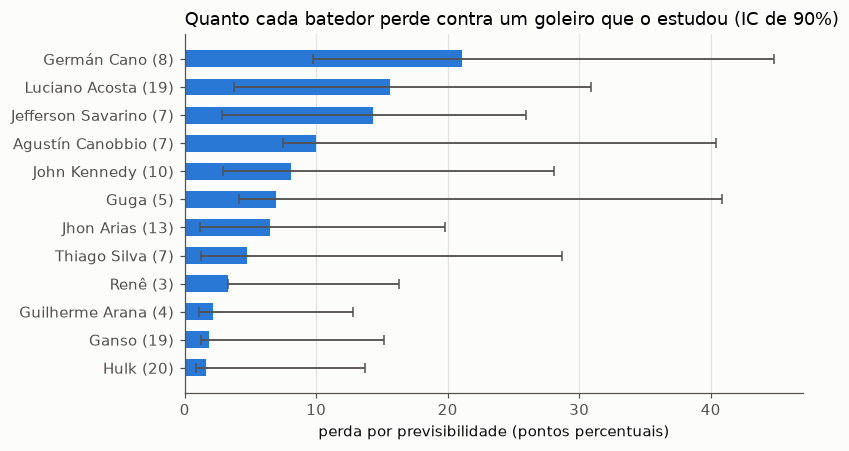

In [18]:
B = 500                                  # réplicas do bootstrap
rng = np.random.default_rng(2026)        # semente fixa: resultados reproduzíveis

def bootstrap_jogador(df_j, B=B):
    """Reamostra as cobranças do jogador com reposição e refaz a análise B vezes.
    Devolve um array B×2 com (v*, chance contra goleiro que estudou)."""
    reps = np.empty((B, 2))
    for b in range(B):
        amostra = df_j.iloc[rng.integers(0, len(df_j), len(df_j))]
        _, _, v_ot_b, _, v_obs_b = analisar_jogador(amostra, P_sim)
        reps[b] = v_ot_b, v_obs_b
    return reps

if not flu.empty and len(tab_flu):
    boot = {nome: bootstrap_jogador(df_j) for nome, df_j in flu.groupby("batedor") if nome in tab_flu.index}
    perdas_boot = pd.DataFrame({n: r[:, 0] - r[:, 1] for n, r in boot.items()})
    ic = pd.DataFrame({"perda": tab_flu["perda por previsibilidade"],
                       "IC 90% (inf.)": perdas_boot.quantile(0.05),
                       "IC 90% (sup.)": perdas_boot.quantile(0.95),
                       "cobranças": tab_flu["cobranças"]}).sort_values("perda", ascending=False)
    display(ic.round(3))

    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    pos = np.arange(len(ic))[::-1]
    ax.barh(pos, ic["perda"] * 100, color=AZUL, height=0.6)
    ax.errorbar(ic["perda"] * 100, pos,
                xerr=[(ic["perda"] - ic["IC 90% (inf.)"]) * 100, (ic["IC 90% (sup.)"] - ic["perda"]) * 100],
                fmt="none", ecolor="#52514e", elinewidth=1.2, capsize=3)
    ax.set_yticks(pos, [f"{n} ({c})" for n, c in zip(ic.index, ic["cobranças"])])
    ax.set_xlabel("perda por previsibilidade (pontos percentuais)")
    ax.set_title("Quanto cada batedor perde contra um goleiro que o estudou (IC de 90%)", loc="left")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

**Leitura.** Os intervalos são largos e se sobrepõem: com 3 a 20 cobranças por jogador, o valor
exato de cada perda não é confiável, e a ordem entre batedores vizinhos na tabela pode mudar. Os
intervalos também ficam **deslocados para cima** do valor calculado, porque reamostrar poucas
cobranças tende a concentrar ainda mais os chutes, o que exagera a previsibilidade; por isso usamos
o bootstrap para medir a **largura** da incerteza, não para corrigir o valor. O que resiste é o
quadro geral: os limites inferiores mais altos são os de Cano (cerca de 10 pontos) e Canobbio
(cerca de 7), enquanto os de Hulk, Ganso e Arana ficam perto de 1 ponto. Acosta e Savarino têm
perda alta no cálculo principal, mas intervalos que descem até 3 ou 4 pontos.

**O Fluminense como time.** Juntando todas as cobranças com a camisa tricolor numa matriz só
(também encolhida em direção à liga simetrizada), vemos se o time, no conjunto, bate de forma previsível.

In [19]:
if not flu.empty:
    tric = flu[flu["time"] == "fluminense"]
    P_flu, x_ot, v_ot, x_obs, v_obs = analisar_jogador(tric, P_sim)
    print(f"{len(tric)} cobranças pelo Fluminense, conversão {tric['gol'].mean():.1%}\n")
    display(pd.DataFrame({"Fluminense (observado)": x_obs, "ótimo para essa matriz": x_ot.values,
                          "liga (observado)": obs_batedor.values}, index=["E", "M", "D"]).round(3))
    print(f"Chance garantida jogando o ótimo: {v_ot:.3f}")
    print(f"Contra um goleiro que estudou o Flu: {v_obs:.3f}  ->  perda por previsibilidade {v_ot - v_obs:.3f}")

85 cobranças pelo Fluminense, conversão 69.4%



,Fluminense (observado),ótimo para essa matriz,liga (observado)
E,0.329,0.368,0.499
M,0.165,0.228,0.071
D,0.506,0.403,0.430


Chance garantida jogando o ótimo: 0.764
Contra um goleiro que estudou o Flu: 0.734  ->  perda por previsibilidade 0.030


**Destros e canhotos: o lado natural.** Até aqui, E/M/D são lados do goleiro. Mas um destro e
um canhoto que chutam "no seu lado preferido" mandam a bola para lados opostos do goleiro, e uma
matriz em E/M/D mistura os dois. Reclassificamos cada cobrança pelo pé do batedor:

| pé | **N** (lado natural) | **M** | **C** (lado contrário) |
|---|---|---|---|
| direito | D do goleiro (esquerda do batedor) | M | E do goleiro |
| esquerdo | E do goleiro | M | D do goleiro |

e fazemos o mesmo com o lado para onde o goleiro foi. A referência continua sendo a liga simetrizada $\bar P$, que não favorece nenhum lado.
Usamos todas as cobranças dos jogadores do elenco (o jeito de bater é do jogador), com $m = 10$, e
comparamos a mesma análise feita nas duas codificações.

In [20]:
NATURAL = {"D": {"D": "N", "M": "M", "E": "C"},   # destro: natural = direita do goleiro
           "E": {"E": "N", "M": "M", "D": "C"}}   # canhoto: natural = esquerda do goleiro
LADOS = ["N", "M", "C"]
M_NATURAL = 10

if not flu.empty:
    nat = flu[flu["pe"].isin(["D", "E"])].copy()
    nat["canto"] = [NATURAL[p][c] for p, c in zip(nat["pe"], nat["canto"])]
    nat["goleiro"] = [NATURAL[p][g] if g in ACOES else "" for p, g in zip(nat["pe"], nat["goleiro"])]
    print(f"{len(nat)} cobranças com o pé anotado\n")

    # Quem vai para onde, e com que sucesso
    goleiro_n = nat.loc[nat["goleiro"] != "", "goleiro"].value_counts(normalize=True).reindex(LADOS, fill_value=0)
    display(pd.DataFrame({"batedor chuta": nat["canto"].value_counts(normalize=True).reindex(LADOS),
                          "goleiro vai": goleiro_n,
                          "conversão do chute": nat.groupby("canto")["gol"].mean().reindex(LADOS)}).round(3))

    # Mesma análise de previsibilidade, com as mesmas cobranças, nas duas codificações
    sem_pe = nat.assign(canto=flu.loc[nat.index, "canto"], goleiro=flu.loc[nat.index, "goleiro"])
    _, x_emd, v_emd, xo_emd, vo_emd = analisar_jogador(sem_pe, P_sim, m=M_NATURAL)
    P_nat, x_nmc, v_nmc, xo_nmc, vo_nmc = analisar_jogador(nat, P_sim, m=M_NATURAL, rotulos=LADOS)

    display(pd.DataFrame(P_nat, index=[f"chuta {l}" for l in LADOS],
                         columns=[f"goleiro {l}" for l in LADOS]).round(3))
    fmt = lambda x: " / ".join(f"{p:.0%}" for p in x)
    display(pd.DataFrame({
        "codificação": ["lados do goleiro (E/M/D)", "lado natural (N/M/C)"],
        "chuta (obs.)": [fmt(xo_emd), fmt(xo_nmc)],
        "ótimo": [fmt(x_emd), fmt(x_nmc)],
        "v* (ótimo)": [v_emd, v_nmc],
        "contra goleiro que estudou": [vo_emd, vo_nmc],
        "perda por previsibilidade": [v_emd - vo_emd, v_nmc - vo_nmc],
    }).set_index("codificação").round(3))


    # Bootstrap: a diferença entre as codificações é robusta?
    dif = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, len(nat), len(nat))
        a_n, a_e = nat.iloc[idx], sem_pe.iloc[idx]
        _, _, v1, _, o1 = analisar_jogador(a_e, P_sim, m=M_NATURAL)
        _, _, v2, _, o2 = analisar_jogador(a_n, P_sim, m=M_NATURAL, rotulos=LADOS)
        dif[b] = (v2 - o2) - (v1 - o1)
    print(f"Perda em lado natural menos perda em E/M/D: {(v_nmc - vo_nmc) - (v_emd - vo_emd):.3f} "
          f"(IC 90%: {np.quantile(dif, 0.05):.3f} a {np.quantile(dif, 0.95):.3f}; "
          f"maior em lado natural em {np.mean(dif > 0):.0%} das réplicas)")

142 cobranças com o pé anotado



,batedor chuta,goleiro vai,conversão do chute
N,0.479,0.613,0.721
M,0.127,0.021,0.611
C,0.394,0.366,0.768


,goleiro N,goleiro M,goleiro C
chuta N,0.637,0.962,0.932
chuta M,0.841,0.085,0.791
chuta C,0.992,0.968,0.513


,chuta (obs.),ótimo,v* (ótimo),contra goleiro que estudou,perda por previsibilidade
codificação,,,,,
lados do goleiro (E/M/D),39% / 13% / 49%,34% / 20% / 46%,0.788,0.776,0.012
lado natural (N/M/C),48% / 13% / 39%,50% / 21% / 29%,0.782,0.749,0.033


Perda em lado natural menos perda em E/M/D: 0.021 (IC 90%: -0.036 a 0.061; maior em lado natural em 64% das réplicas)


**Leitura.** Três coisas aparecem quando se separa destros de canhotos:
- **Os goleiros sabem do lado natural.** Eles vão para o lado natural do batedor em 61% das vezes,
  enquanto os batedores chutam lá em 48%. É o mesmo padrão relatado na literatura [6, 11].
- **O chute no lado contrário é mais fraco quando o goleiro acerta.** Com o goleiro no lado certo,
  o chute natural entra 64% das vezes e o contrário só 51%. Por isso o ótimo manda chutar **menos**
  no lado contrário (29%) do que o elenco chuta (39%), e mais no meio (21% contra 13%).
- **Misturar destros e canhotos pode esconder previsibilidade, mas aqui o efeito é incerto.** Com
  as mesmas 142 cobranças e a mesma referência, a perda por previsibilidade é 1,2 ponto em E/M/D e
  3,3 pontos em lado natural. O mecanismo faz sentido: em E/M/D, o destro que vai sempre à direita
  do goleiro e o canhoto que vai sempre à esquerda se compensam, e o elenco parece mais equilibrado
  do que é. Mas o bootstrap mostra que a diferença não é robusta (intervalo de −3,6 a +6,1 pontos;
  ela é positiva em só 64% das réplicas). Os dois primeiros resultados acima, sobre goleiros e
  lado contrário, são os que valem destacar.

**Pressão nas disputas.** Se houver cobranças de disputa marcadas com `errar_elimina`, comparamos
a conversão nas cobranças "se errar, perde" com as demais. (Com poucas disputas a amostra é
minúscula — o número serve como indício, não como estimativa confiável de $\delta$.)

In [21]:
if not flu.empty and "errar_elimina" in flu and flu["disputa"].sum() > 0:
    disp = flu[flu["disputa"] == 1].copy()
    disp["situação"] = np.where(disp["errar_elimina"] == 1, "errar elimina", "demais")
    display(disp.groupby("situação")["gol"].agg(cobranças="count", conversão="mean").round(3))

,cobranças,conversão
situação,,
demais,31,0.645
errar elimina,2,0.500


**Quem escalar, se o goleiro estudou o Flu?** Na Seção 3.6 a escalação ótima já foi calculada, e
com o elenco real ela seria só "os 5 maiores $v_k^*$": com a mesma queda sob pressão para todos, a
ordem quase não importa. A pergunta útil é outra. Cada batedor $k$ tem dois números: $v_k^*$, a
chance que ele **garante** jogando a estratégia ótima, e $v_k^{\text{obs}}$, a chance dele
**mantendo seus hábitos** contra um goleiro que os estudou. Comparamos três cenários contra um
adversário médio da liga, com a mesma queda sob pressão $\delta = $ `DELTA_PADRAO` para todos
(ilustrativa, pois não há dados para estimá-la por jogador):

1. **Batedores imprevisíveis:** todos jogam a estratégia ótima; usa-se $v_k^*$.
2. **Goleiro estudou, escalação ingênua:** a escalação do cenário 1 (escolhida por $v_k^*$), mas
   cada batedor rende $v_k^{\text{obs}}$.
3. **Goleiro estudou, escalação otimizada:** a escalação é escolhida de novo, já usando $v_k^{\text{obs}}$.

Em cada cenário otimizamos quem bate e em que ordem, enumerando as $8!/3! = 6720$ escalações dos 8
melhores candidatos, com o Flu batendo primeiro.

In [22]:
DELTA_PADRAO = 0.08

def melhor_escalacao(v):
    """Melhor escolha e ordem de 5 entre os 8 maiores v (Flu bate primeiro)."""
    candidatos = v.sort_values(ascending=False).iloc[:8]
    delta_k = {n: DELTA_PADRAO for n in candidatos.index}
    (p, ordem), _ = otimizar_escalacao(candidatos, delta_k, adversario, delta_adv, bate_primeiro=True)
    return p, list(ordem)

def avaliar(ordem, v):
    """P(vencer) com os 5 da ordem e os 3 seguintes do elenco (por v) na morte súbita."""
    seq = ordem + [n for n in v.sort_values(ascending=False).index if n not in ordem][:3]
    return prob_vitoria([v[n] for n in seq], adversario, [DELTA_PADRAO] * len(seq), delta_adv, restoA=RESTO)

if not flu.empty and len(tab_flu) >= 5:
    v_ot = tab_flu["v* (ótimo)"]
    v_hab = tab_flu["contra goleiro que estudou"]
    p1, ordem1 = melhor_escalacao(v_ot)
    p2 = avaliar(ordem1, v_hab)
    p3, ordem3 = melhor_escalacao(v_hab)
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame({
            "P(vencer a disputa)": [p1, p2, p3],
            "escalação": [" → ".join(ordem1), " → ".join(ordem1), " → ".join(ordem3)]},
            index=["1. batedores imprevisíveis", "2. goleiro estudou, escalação ingênua",
                   "3. goleiro estudou, escalação otimizada"]).round(3))
    print(f"Reescalar levando a previsibilidade em conta: {p3 - p2:+.1%}")
    print(f"Ficar imprevisível (jogar a estratégia ótima): mais {p1 - p3:+.1%}")
    print("Saem da escalação:", ", ".join(n for n in ordem1 if n not in ordem3) or "-",
          "| entram:", ", ".join(n for n in ordem3 if n not in ordem1) or "-")

    # O PL de designação (Seção 3.6) com TODOS os candidatos; a enumeração acima usou só os 8 melhores
    ordem_pl, _, _, _ = escalacao_designacao(v_hab, {n: DELTA_PADRAO for n in v_hab.index}, adversario, delta_adv)
    print(f"\nPL de designação com os {len(v_hab)} candidatos ({perm(len(v_hab), 5):,} escalações possíveis): "
          + " → ".join(ordem_pl))
    print(f"P(vencer) = {avaliar(ordem_pl, v_hab):.4f}  (enumeração dos 8 melhores: {p3:.4f})")
    for n in sorted(set(ordem_pl) ^ set(ordem3)):
        print(f"  {n}: chance contra goleiro que estudou = {v_hab[n]:.4f}")
elif not flu.empty:
    print("São necessários pelo menos 5 batedores com", MIN_COBRANCAS, "cobranças ou mais.")

,P(vencer a disputa),escalação
1. batedores imprevisíveis,0.545,Thiago Silva → Hulk → Guilherme Arana → John Kennedy → Jefferson Savarino
"2. goleiro estudou, escalação ingênua",0.421,Thiago Silva → Hulk → Guilherme Arana → John Kennedy → Jefferson Savarino
"3. goleiro estudou, escalação otimizada",0.447,Thiago Silva → Guilherme Arana → Hulk → Renê → John Kennedy


Reescalar levando a previsibilidade em conta: +2.6%
Ficar imprevisível (jogar a estratégia ótima): mais +9.8%
Saem da escalação: Jefferson Savarino | entram: Renê

PL de designação com os 12 candidatos (95,040 escalações possíveis): Guilherme Arana → Thiago Silva → Hulk → Renê → Guga
P(vencer) = 0.4471  (enumeração dos 8 melhores: 0.4471)
  Guga: chance contra goleiro que estudou = 0.7883
  John Kennedy: chance contra goleiro que estudou = 0.7883


**Os cenários resistem à incerteza?** Usamos as mesmas 500 réplicas do bootstrap por jogador
(cada uma com seus próprios $v_k^*$ e $v_k^{\text{obs}}$) e recalculamos as três probabilidades, mantendo
fixas as escalações encontradas acima.

,P(vencer),IC 90% (inf.),IC 90% (sup.)
1. imprevisíveis,0.545,0.537,0.585
"2. estudou, ingênua",0.421,0.289,0.461
"3. estudou, otimizada",0.447,0.301,0.465


Ganho de escolha (3 − 2): IC 90% de -3.7% a +6.0%; positivo em 63% das réplicas
Ganho de imprevisibilidade (1 − 3): IC 90% de +10.4% a +25.7%; positivo em 100% das réplicas


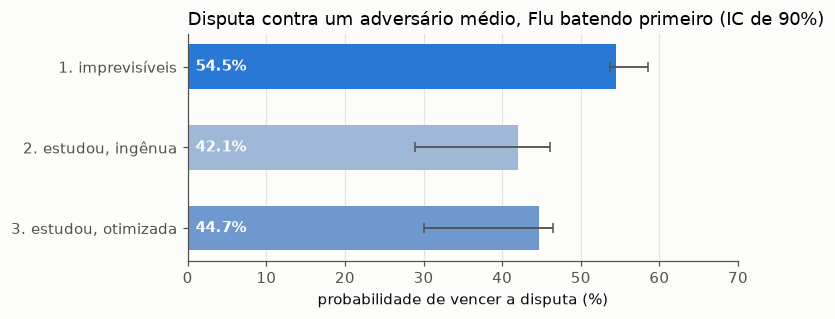

In [23]:
# Incerteza dos cenários: as mesmas réplicas do bootstrap por jogador, com as escalações fixas
if not flu.empty and len(tab_flu) >= 5:
    nomes = list(boot)
    reps_cen = np.empty((B, 3))
    for b in range(B):
        v_ot_b = pd.Series({n: boot[n][b, 0] for n in nomes})
        v_hab_b = pd.Series({n: boot[n][b, 1] for n in nomes})
        reps_cen[b] = avaliar(ordem1, v_ot_b), avaliar(ordem1, v_hab_b), avaliar(ordem3, v_hab_b)
    rotulos = ["1. imprevisíveis", "2. estudou, ingênua", "3. estudou, otimizada"]
    pontos = np.array([p1, p2, p3])
    inf, sup = np.quantile(reps_cen, 0.05, axis=0), np.quantile(reps_cen, 0.95, axis=0)
    display(pd.DataFrame({"P(vencer)": pontos, "IC 90% (inf.)": inf, "IC 90% (sup.)": sup}, index=rotulos).round(3))
    for nome, d in [("escolha (3 − 2)", reps_cen[:, 2] - reps_cen[:, 1]),
                    ("imprevisibilidade (1 − 3)", reps_cen[:, 0] - reps_cen[:, 2])]:
        print(f"Ganho de {nome}: IC 90% de {np.quantile(d, 0.05):+.1%} a {np.quantile(d, 0.95):+.1%}; "
              f"positivo em {np.mean(d > 0):.0%} das réplicas")

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.barh(range(3)[::-1], pontos * 100, color=[AZUL, "#9fb8d8", "#6f98cf"], height=0.55)
    ax.errorbar(pontos * 100, range(3)[::-1], xerr=[(pontos - inf) * 100, (sup - pontos) * 100],
                fmt="none", ecolor="#52514e", elinewidth=1.2, capsize=3)
    for y, pt in zip(range(3)[::-1], pontos):
        ax.text(1, y, f"{pt:.1%}", va="center", color="#fcfcfb", fontweight="bold")
    ax.set_yticks(range(3)[::-1], rotulos); ax.set_xlim(0, 70)
    ax.set_xlabel("probabilidade de vencer a disputa (%)")
    ax.set_title("Disputa contra um adversário médio, Flu batendo primeiro (IC de 90%)", loc="left")
    ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

**Leitura.** É aqui que o modelo vira uma recomendação para o treinador:
- Se o goleiro adversário estudou o Flu e os batedores mantêm os hábitos, a escalação "pelos
  melhores batedores" vence 42,1% das disputas contra um adversário médio, e não 54,5%.
- **Treinar os batedores para variar o canto** é o ganho grande e robusto: cerca de 10 pontos, e
  positivo em todas as 500 réplicas do bootstrap.
- **Escolher os batedores levando a previsibilidade em conta** (sai Savarino, que chuta 86% num
  canto só, entra Renê) recupera 2,6 pontos no cálculo principal, mas esse ganho **não resiste à
  incerteza**: o intervalo vai de −3,7 a +6,0 pontos. Com tão poucas cobranças por jogador, não dá
  para afirmar quem é o quinto melhor batedor contra um goleiro que estudou o time.
- A **ordem**, com o mesmo $\delta$ para todos, muda menos de 2 pontos.
- O **PL de designação** da Seção 3.6, rodado com os 12 candidatos (95 040 escalações possíveis, contra
  as 6 720 enumeradas com os 8 melhores), chega à mesma probabilidade de vencer. A escalação difere
  só por trocar John Kennedy por Guga, que têm exatamente a mesma chance contra um goleiro que estudou.

Os números absolutos dependem do adversário e do $\delta$, que são ilustrativos. O resultado que
sobrevive à incerteza é este: **o que muda a disputa é a imprevisibilidade dos batedores**, muito
mais do que a ordem ou a troca de um batedor.

## 4. Discussão

### 4.1 O que o modelo diz
- **A chance de gol de equilíbrio é cerca de 86–87%**, conforme a versão do modelo (85,9% no
  2×2, 87,0% no 3×3 com $m = 10$), muito perto da conversão observada de 86,3% na liga espanhola.
  É o que a teoria prevê: se batedores e goleiros jogam perto do equilíbrio, a conversão média fica
  perto do valor do jogo.
- **A indiferença aparece na solução e nos dados:** contra o goleiro ótimo, chutar em E, M ou D dá
  exatamente a mesma chance de gol. São as folgas complementares do PL. Nos 549 pênaltis, a
  conversão por canto do batedor é de fato estatisticamente igual (p ≈ 0,67), como no teste de
  Chiappori et al. [5] e Palacios-Huerta [6]. Para o goleiro, esquerda e direita também empatam,
  mas ficar no meio segura mais, coerente com o modelo recomendar mais goleiro no meio do que se vê.
- **O dual tem significado próprio:** a estratégia do goleiro não precisou de outro modelo; ela é
  a solução dual do problema do batedor.

### 4.2 Onde o modelo erra (dados da liga)
- **Chutes no meio.** O modelo recomenda chutar no meio em 11% das vezes; os jogadores chutam em
  7%. A diferença é pequena e depende da célula "meio × goleiro parado", que tem só 6 cobranças. A
  escolha da referência dessa célula importa: agrupada com os casos em que o goleiro pulou e acertou
  o lado (referência de 72%, a escolha mais simples), o modelo recomendaria 17% de chutes no meio. Tratar o goleiro parado como situação própria, com referência baixa vinda do
  conhecimento do jogo, aproxima o modelo do comportamento real. O que sobra da diferença pode ser
  comportamental: errar uma cavadinha custa caro em reputação, um "custo" que não está na matriz.
- **Esquerda × direita.** Os batedores vão mais para a esquerda do goleiro (50%) do que o modelo
  prevê (36%). Uma explicação é a **agregação**: uma única matriz para destros e canhotos, que têm
  "lados naturais" opostos. Por isso a literatura analisa os dados por lado natural [5, 6]. Os
  dados da liga não informam o pé, mas os do Fluminense sim, e lá o mecanismo aparece: os goleiros
  vão ao lado natural do batedor 61% das vezes. O efeito da agregação sobre a medida de
  previsibilidade, porém, não foi robusto (Seção 3.7).
- **Os batedores não são iguais**, o que motivou as matrizes individuais das Seções 3.6 e 3.7.

### 4.3 O que os dados do Fluminense mostram
Foram anotadas 142 cobranças de 30 batedores (85 com a camisa do Fluminense, 32 delas em disputas).
- **O Fluminense converte pouco.** 69,4% com a camisa tricolor, contra 86,3% na liga espanhola. Com
  a matriz do time (encolhida em direção à liga simetrizada), jogar o ótimo garantiria 76,4%; a distância até
  o observado sugere que o problema não é só de escolha de canto, mas também de execução. A matriz
  do Flu mostra onde: quando o goleiro **acerta o lado**, o Flu marca 48,5% (E) e 57,6% (D), contra
  70% e 78% na liga; quando o goleiro erra, as chances são parecidas com as da liga. Ou seja, o
  chute tricolor é mais fácil de defender quando o goleiro adivinha o canto.
- **O time, no conjunto, não é muito previsível.** O Flu chuta E/M/D em 33% / 16% / 51%, e o ótimo
  para a sua matriz é 37% / 23% / 40%. Um goleiro que estudasse o time "inteiro" ganharia só
  3,0 pontos percentuais (76,4% → 73,4%). O Flu chuta **mais no meio** (16%) do que os batedores da
  liga (7%), e o modelo diz que poderia chutar ainda mais, porque nos chutes fora do meio o time
  sofre quando o goleiro acerta o lado.
- **Individualmente, alguns batedores são muito previsíveis.** A perda por previsibilidade é
  pequena para Hulk (1,6 p.p.) e Ganso (1,9 p.p.), mas grande para **Germán Cano (21,1 p.p.)**,
  **Luciano Acosta (15,6 p.p.)** e **Jefferson Savarino (14,3 p.p.)**. Savarino chutou 86% das vezes
  no mesmo canto; Acosta nunca chutou no meio e foi 63% para a esquerda; Cano foi 38% no meio, onde
  um goleiro que espera parado defende quase tudo. Contra um goleiro que estudou esses batedores, a
  chance deles cai de ~85% para ~64–72%. Os três são destros, e Savarino e Acosta concentram os
  chutes na esquerda do goleiro, que para destro é o lado contrário, o mais fraco quando o goleiro
  acerta. Esses valores são incertos: os intervalos do bootstrap são largos (os de Acosta e Savarino
  descem até 3 ou 4 pontos), e Cano tem só 8 cobranças. O quadro geral, de quem é muito ou pouco
  previsível, é o que resiste.
- **Destros e canhotos.** Separando pelo pé, os goleiros vão ao lado natural do batedor 61% das
  vezes, e o chute no lado contrário é o que mais sofre quando o goleiro acerta (51% de gols, contra
  64% no lado natural). O ótimo manda chutar menos no lado contrário e mais no meio. Em lado
  natural, a perda por previsibilidade do elenco sobe de 1,2 para 3,3 pontos (em E/M/D, destros e
  canhotos se compensam), mas o bootstrap mostra que essa diferença não é robusta.
- **Disputas.** Nas disputas, o Flu converteu 62,5% (20 de 32), contra 73,6% nas cobranças durante
  o jogo. A diferença vai na direção do efeito de pressão, mas com 32 cobranças o intervalo de
  confiança é grande demais para afirmar que ela existe. Só 2 cobranças foram do tipo "se errar,
  perde", então $\delta$ não pôde ser estimado e continua ilustrativo.
- **Quem escalar.** Escolher simplesmente os cinco maiores $v_k^*$ só faz sentido se os batedores
  forem imprevisíveis. Contra um goleiro que estudou o Flu, essa escalação vence 42,1% das disputas
  contra um adversário médio, e não 54,5%. Treinar os batedores para variar o canto vale cerca de
  10 pontos, e esse ganho é positivo em todas as réplicas do bootstrap. Reescolher levando a
  previsibilidade em conta (sai Savarino, entra Renê) recupera 2,6 pontos, mas o intervalo vai de
  −3,7 a +6,0: não dá para afirmar a troca. A ordem, com o mesmo $\delta$ para todos, muda menos de
  2 pontos. É o resultado mais prático do trabalho, e o único que resiste à incerteza: **o que muda
  a disputa é a imprevisibilidade**.

### 4.4 Limitações
- **Pouca informação por jogador:** o batedor com mais dados tem 20 cobranças, e os intervalos do
  bootstrap mostram quanto isso pesa: as perdas individuais e o ganho de trocar um batedor são
  incertos. O encolhimento é o que torna a análise individual possível, mas a escolha de $m$ e da
  referência de M×M (15%) é um julgamento; elas poderiam ser estimadas por validação cruzada ou por
  um modelo bayesiano hierárquico.
- **Anotação por vídeo:** canto e lado do goleiro foram classificados a olho, por duas pessoas,
  com a regra das três faixas do gol. Entre meio e lado há casos de fronteira, e a classe M é
  justamente a mais rara. 7 cobranças sem vídeo adequado ficaram de fora.
- **Referência das matrizes individuais:** a matriz da liga foi simetrizada porque não informa o
  pé. Com o pé dos batedores da liga, a referência poderia ser montada em lado natural.
- **Seleção da amostra:** a carreira dos batedores no Transfermarkt não inclui disputas, e para o
  Hulk só usamos as 20 cobranças mais recentes de 144. Há cobranças contra goleiros diferentes, em
  épocas e clubes diferentes, misturadas numa matriz só.
- **Simultaneidade:** alguns batedores esperam o goleiro se mexer (paradinha); aí o jogo deixa de
  ser simultâneo e vira sequencial.
- **Três ações:** chute alto/baixo e a força do chute ficam de fora.

### 4.5 A disputa de pênaltis
- **Sem pressão, a ordem dos 5 batedores não importa**, um resultado talvez contraintuitivo que
  vale para qualquer conjunto de probabilidades independentes. Só **quem** bate importa.
- **Com pressão diferente entre jogadores, a ordem importa**, e a regra que emerge é colocar o
  batedor mais frio na 5ª cobrança (Seção 3.6, batedores fictícios).
- **A escalação é um problema de designação.** Linearizando a probabilidade de vencer em torno de um
  time médio, escolher quem bate em cada posição vira um PL de designação. Pela unimodularidade
  total, a solução sai inteira sem exigir variáveis inteiras. Os pesos da linearização mostram o
  porquê dos resultados anteriores: a chance de cada batedor pesa quase igual nas cinco posições, e a
  pressão se concentra na 5ª cobrança. Nos testes, o PL achou a mesma escalação ótima da enumeração
  exata, em milissegundos em vez de segundos, e com 12 candidatos (95 040 escalações) chegou a uma
  escalação de mesma probabilidade.
- **Vantagem de bater primeiro:** no modelo ela aparece **só** por causa da pressão (sem pressão,
  times iguais têm 50%). A literatura discorda sobre o tamanho real desse efeito: 60,5% em [7]
  contra nenhuma vantagem significativa em [8], com uma amostra maior. O modelo mostra qual
  mecanismo produziria o efeito, mas não diz se ele existe.

### 4.6 Extensões possíveis
- **Goleiro específico:** o goleiro também tem sua matriz; na disputa, cada par batedor × goleiro é
  um jogo diferente.
- **Lado natural na liga:** a análise por lado natural foi feita só com os dados do Flu; com o pé
  dos batedores da liga, a matriz de referência também poderia ser montada em lado natural, em vez
  de simetrizada.
- **Modelo bayesiano completo** para as matrizes individuais.
- **Designação com objetivo mais preciso:** a linearização é feita uma vez, em torno de um time
  médio. Ela poderia ser refeita em torno da escalação encontrada, repetindo até a escalação parar de
  mudar, o que aproxima melhor a probabilidade de vencer quando os batedores são muito diferentes.

### 4.7 Conclusão
Um PL de 4 variáveis resolve o pênalti, e o seu dual entrega de graça a estratégia do goleiro. Um
segundo PL, de designação, escala os batedores na disputa. Com dados reais, o equilíbrio de von
Neumann acerta a conversão média da liga quase em cheio, e a previsão de indiferença passa no teste
estatístico. O tratamento das células com poucos dados mostrou que a regularização não é só um
detalhe técnico: escolher bem para onde puxar uma célula, usando conhecimento do jogo, aproximou a
previsão do comportamento real.

Aplicado ao Fluminense, o modelo não "explica" sozinho as derrotas em disputas: o time converte
pouco porque seus chutes são fáceis de defender quando o goleiro acerta o lado. Mas ele aponta onde
há ganho: batedores previsíveis, como Cano, Acosta e Savarino, deixam de 14 a 21 pontos percentuais
na mesa contra um goleiro que estudou suas cobranças, e numa disputa isso pesa muito mais do que a
ordem dos batedores. Com a margem de erro medida por bootstrap, a recomendação que sobrevive é
treinar os batedores para variar o canto; quem exatamente escalar fica incerto com os dados
disponíveis.

## Referências

1. J. von Neumann. Zur Theorie der Gesellschaftsspiele. *Mathematische Annalen*, 100:295–320, 1928.
2. J. von Neumann, O. Morgenstern. *Theory of Games and Economic Behavior*. Princeton University Press, 1944.
3. G. B. Dantzig. A proof of the equivalence of the programming problem and the game problem. In
   T. C. Koopmans (ed.), *Activity Analysis of Production and Allocation*, Wiley, 1951.
4. I. Adler. The equivalence of linear programs and zero-sum games. *International Journal of Game
   Theory*, 42:165–177, 2013.
5. P.-A. Chiappori, S. Levitt, T. Groseclose. Testing mixed-strategy equilibria when players are
   heterogeneous: the case of penalty kicks in soccer. *American Economic Review*, 92(4):1138–1151, 2002.
6. I. Palacios-Huerta. Professionals play minimax. *Review of Economic Studies*, 70(2):395–415, 2003.
7. J. Apesteguia, I. Palacios-Huerta. Psychological pressure in competitive environments: evidence
   from a randomized natural experiment. *American Economic Review*, 100(5):2548–2564, 2010.
8. M. Kocher, M. Lenz, M. Sutter. Psychological pressure in competitive environments: new evidence
   from randomized natural experiments. *Management Science*, 58(8):1585–1591, 2012.
9. M. Tambe. *Security and Game Theory: Algorithms, Deployed Systems, Lessons Learned*. Cambridge University Press, 2011.
10. M. Bowling, N. Burch, M. Johanson, O. Tammelin. Heads-up limit hold'em poker is solved. *Science*, 347(6218):145–149, 2015.
11. J. Sentana Lledó. *The behaviour of players in games with a mixed strategy Nash equilibrium:
    empirical evidence from penalty kicks*. University of Essex, 2015.
12. G. Jordet, E. Hartman, C. Visscher, K. Lemmink. Kicks from the penalty mark in soccer: the roles
    of stress, skill, and fatigue for kick outcomes. *Journal of Sports Sciences*, 25(2):121–129, 2007.
13. Slides da disciplina COS360: aulas 3 (*linear programs*), 4 (*minimax and planning*), 5 (*network
    flow problems*: designação e soluções inteiras), 6 (*LP duality*), 7 (*dual flows and
    algorithms*: simplex), 8 (*least squares*) e 10 (*regularization*).
14. B. Efron, R. J. Tibshirani. *An Introduction to the Bootstrap*. Chapman & Hall, 1993.